# 03 — Recherche en bibliothèque : nettoyer, comparer, retrouver

**Objectif.** Construire la brique de base de tout le pipeline : un moteur qui, pour un spectre requête, retrouve les spectres les plus ressemblants parmi les 2,5 millions du train. Puis mesurer ce qu'il vaut sur notre validation.

On en tire deux mesures :
- en **condition classe 1** (des spectres de la molécule mesurés ailleurs existent) : c'est la recherche en bibliothèque classique ; on s'attend à un bon score ;
- en **condition classe 2** (aucun spectre de la molécule) : le score doit être **exactement 0**, puisque la bonne structure n'a aucun spectre à retrouver. C'est notre test anti-fuite.

Ce notebook remplace la vectorisation de `01_explore` (grille de 0,1 Da + cosinus) par une méthode standard du domaine : nettoyage des spectres + **similarité d'entropie**.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import casmi

pd.set_option("display.width", 140)

## 1. Nettoyer les spectres

Un spectre brut du test a ~230 pics, dont l'immense majorité est du bruit (93 % sous 1 % du pic de base). Le nettoyage (`casmi.clean_peaks`, réglages recommandés par les auteurs de la similarité d'entropie) :

1. **retire tout ce qui est au-dessus de précurseur − 1,6 Da** : le précurseur et ses isotopes ne disent rien de la structure (sa masse est déjà connue par ailleurs) ;
2. **retire les pics sous 1 %** du pic de base ;
3. **fusionne les pics distants de moins de 0,05 Da** (doublons de mesure) ;
4. **normalise** les intensités pour qu'elles somment à 1.

Les 2,5 M spectres du train ont été nettoyés une fois pour toutes (4 minutes) et stockés à plat dans `data/processed/library_clean.npz`.

In [2]:
meta = casmi.load_train_meta(["ingest_lib", "normalized_smiles", "ionization_mode", "instrument_type",
                              "precursor_mz", "adduct", "num_peaks"])
structures = pd.read_parquet(casmi.paths.processed / "structures.parquet").set_index("normalized_smiles")
meta["key"] = meta["normalized_smiles"].map(structures["key"])
meta["exact_mass"] = meta["normalized_smiles"].map(structures["exact_mass"])
meta["source"] = meta["ingest_lib"] + " / " + casmi.instrument_family(meta["instrument_type"])

library = casmi.build_clean_library()
n_clean = np.diff(library["offsets"])
print(f"{len(n_clean):,} spectres, {len(library['mz']):,} pics nettoyés")
print(f"pics par spectre : brut médiane {meta['num_peaks'].median():.0f} -> nettoyé médiane {np.median(n_clean):.0f}")

2,539,608 spectres, 59,672,246 pics nettoyés
pics par spectre : brut médiane 42 -> nettoyé médiane 11


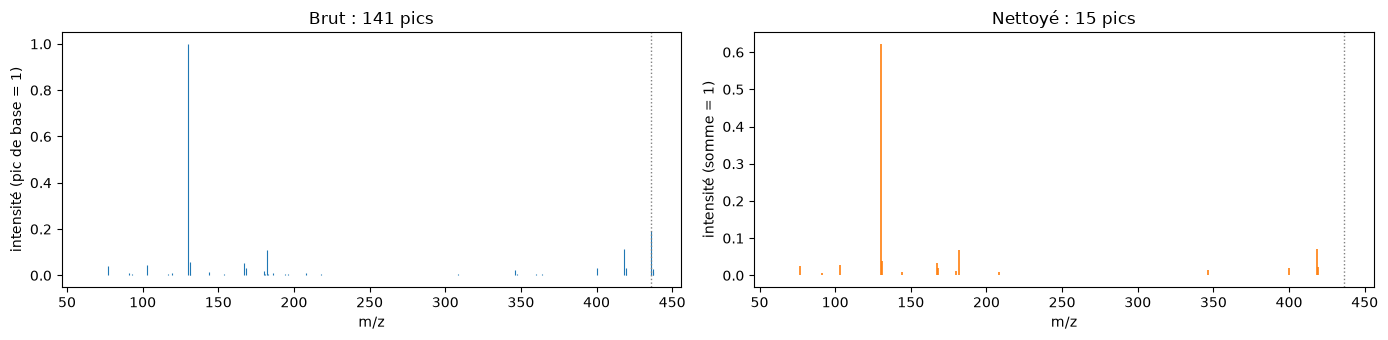

In [3]:
# Un spectre timsTOF de enveda-np-examples, avant / après nettoyage
row = meta.index[meta["ingest_lib"] == "enveda-np-examples"][3]
raw = casmi.load_train_spectra(np.array([row])).iloc[0]
clean = casmi.library_peaks(library, row)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharex=True)
axes[0].vlines(raw["ms2_mzs"], 0, raw["ms2_normalized_intensities"], lw=0.8)
axes[0].set(title=f"Brut : {len(raw['ms2_mzs'])} pics", xlabel="m/z", ylabel="intensité (pic de base = 1)")
axes[1].vlines(clean[:, 0], 0, clean[:, 1], lw=1.2, color="C1")
axes[1].set(title=f"Nettoyé : {len(clean)} pics", xlabel="m/z", ylabel="intensité (somme = 1)")
for ax in axes:
    ax.axvline(meta.at[row, "precursor_mz"], color="grey", ls=":", lw=1)
plt.tight_layout()
plt.show()

## 2. La similarité d'entropie

Pour comparer deux spectres, `01_explore` utilisait le cosinus sur une grille de 0,1 Da. Deux défauts : une grille coupe arbitrairement (deux pics à 0,02 Da d'écart peuvent tomber dans deux cases différentes), et le cosinus est dominé par les quelques pics les plus intenses.

La **similarité d'entropie** (Li et al., *Nature Methods* 2021) apparie les pics avec une tolérance (0,02 Da) plutôt qu'une grille, et pondère les intensités de façon à donner plus de poids aux petits pics informatifs. Elle vaut 1 pour deux spectres identiques, 0 sans aucun pic commun. Sur des benchmarks publics, elle retrouve mieux les molécules que le cosinus.

On utilise son implémentation rapide **FlashEntropy** (paquet `ms_entropy`), qui interroge des millions de spectres en quelques millisecondes grâce à un index.

**Astuce de masse neutre.** Dans l'index, chaque spectre est rangé par la **masse neutre** de sa structure plutôt que par le m/z mesuré. Ainsi un spectre `[M+H]+` et un spectre `[M+Na]+` de la même molécule tombent dans la même fenêtre. Pour une requête, la masse neutre se calcule à partir du précurseur et de l'adduit (`casmi.neutral_mass`), comme on le fera pour le test.

Deux modes de recherche :
- **identité** : seulement les références de même masse neutre (±10 ppm) ; c'est la recherche en bibliothèque ;
- **hybride** : toutes masses, en appariant aussi les pics décalés de la différence de masse ; c'est la recherche d'**analogues** (molécules voisines), qui servira pour la classe 2.

In [4]:
t = time.time()
index = casmi.SpectralIndex(library, meta)   # construit une fois (~9 min), puis relu du disque
print(f"index prêt en {time.time() - t:.0f} s :",
      {pol: f"{len(r):,} spectres" for pol, r in index.rows.items()})

index prêt en 11 s : {'positive': '1,863,424 spectres', 'negative': '636,795 spectres'}


## 3. Évaluer en condition classe 1 et classe 2

Pour chaque tirage de spectres requêtes (graines 0 à 4) et chaque condition :

1. `casmi.reference_mask` donne les lignes du train autorisées comme références :
   - **classe 1** : tout, sauf, pour chaque molécule de validation, les spectres de **sa source requête** ;
   - **classe 2** : tout, sauf **tous** les spectres des molécules de validation ;
2. `casmi.spectrum_hits` interroge l'index pour chaque spectre requête (mode identité) et garde, pour chaque structure touchée, sa meilleure similarité ;
3. `casmi.aggregate_hits` combine les spectres d'une même molécule, par **somme** (une structure retrouvée par plusieurs spectres gagne) ou par **maximum** ;
4. on classe les structures et on calcule le MRR@25.

Chaque condition prend environ une minute par tirage.

In [5]:
val_structures, val_queries = casmi.load_validation()
counts = casmi.spectra_count_distribution()
row_keys = meta["key"].to_numpy()
masks = {cond: casmi.reference_mask(meta, val_queries, cond) for cond in ["class1", "class2"]}

results = []   # une ligne par (condition, tirage, agrégation, molécule)
hits_store = {}
for seed in range(5):
    draw = casmi.sample_queries(val_queries, counts, seed)
    for cond, allowed in masks.items():
        t = time.time()
        hits = casmi.spectrum_hits(index, library, row_keys, draw, allowed)
        hits_store[(cond, seed)] = hits
        for how in ["sum", "max"]:
            ev = casmi.evaluate(casmi.aggregate_hits(hits, how), val_structures)
            results.append(ev.assign(condition=cond, seed=seed, aggregate=how))
        print(f"tirage {seed} {cond} : {time.time() - t:.0f} s")

results = pd.concat(results, ignore_index=True)

tirage 0 class1 : 45 s


tirage 0 class2 : 44 s


tirage 1 class1 : 44 s


tirage 1 class2 : 44 s


tirage 2 class1 : 41 s


tirage 2 class2 : 43 s


tirage 3 class1 : 44 s


tirage 3 class2 : 41 s


tirage 4 class1 : 41 s


tirage 4 class2 : 41 s


In [6]:
# MRR@25 moyen sur les 5 tirages (± écart-type entre tirages)
per_draw = results.groupby(["condition", "aggregate", "subset", "seed"])["rr"].mean()
summary = per_draw.groupby(["condition", "aggregate", "subset"]).agg(["mean", "std"]).round(3)
summary.unstack("subset")

mean                       std            
subset              A_np_examples B_np_public A_np_examples B_np_public
condition aggregate                                                    
class1    max               0.924       0.494         0.007       0.007
          sum               0.931       0.488         0.008       0.006
class2    max               0.000       0.000         0.000       0.000
          sum               0.000       0.000         0.000       0.000

**Molécules « atteignables » en classe 1.** Une molécule de validation n'est retrouvable en classe 1 que si elle a au moins un spectre de référence **hors de sa source requête**. C'est le cas de toutes les molécules de A (elles ont par construction des spectres dans d'autres bibliothèques), mais pas de toutes celles de B : beaucoup n'ont été mesurées que par une seule source. Pour ces dernières, la classe 1 ne veut rien dire. On calcule donc aussi le score **parmi les molécules atteignables**, qui est le vrai score de la recherche en bibliothèque.

In [7]:
val_keys = set(val_structures["key"])
in_val = meta["key"].isin(val_keys)
reachable_keys = set(meta.loc[masks["class1"] & in_val.to_numpy(), "key"])
val_structures["atteignable"] = val_structures["key"].isin(reachable_keys)
print(val_structures.groupby("subset")["atteignable"].mean().round(3))

c1_all = results[results["condition"] == "class1"].merge(val_structures[["molecule_id", "atteignable"]], on="molecule_id")
(c1_all[c1_all["atteignable"]]
   .groupby(["aggregate", "subset", "seed"])["rr"].mean()
   .groupby(["aggregate", "subset"]).agg(["mean", "std"]).round(3).unstack("subset"))

subset
A_np_examples    1.000
B_np_public      0.595
Name: atteignable, dtype: float64


mean                       std            
subset    A_np_examples B_np_public A_np_examples B_np_public
aggregate                                                    
max               0.924       0.830         0.007       0.011
sum               0.931       0.821         0.008       0.010

**Lecture.**
- **Classe 2 : 0 exactement**, sur A comme sur B. Aucune fuite : quand tous les spectres d'une molécule sont cachés, la recherche d'identité ne peut plus la retrouver. Le découpage du notebook 02 est sain.
- **Classe 1** : parmi les molécules atteignables, c'est le score qu'on peut espérer sur les ~16 % de molécules du test qui ont des spectres publics. Le forum annonce ~0,93 pour une bonne recherche en bibliothèque sur ce type de molécules : on doit retrouver cet ordre de grandeur. L'écart-type entre tirages donne une idée du bruit de notre mesure.
- **Somme ou maximum** : on garde l'agrégation qui gagne sur A **et** sur B.

## 4. Diagnostics en classe 1

Trois questions :
1. **Quand on échoue, pourquoi ?** Soit la bonne structure est retrouvée mais mal classée, soit elle n'est pas retrouvée du tout (aucune référence de même masse ne lui ressemble assez).
2. **L'instrument de la requête compte-t-il ?** Dans B, les requêtes viennent de QTOF, d'Orbitrap, etc. C'est l'occasion de vérifier le choix « QTOF d'abord » du notebook 02.
3. **Le nombre de spectres par molécule compte-t-il ?**

In [8]:
best_how = summary.loc[("class1",)]["mean"].unstack("subset").mean(axis=1).idxmax()
c1 = c1_all[(c1_all["aggregate"] == best_how) & c1_all["atteignable"]].copy()
print("agrégation retenue :", best_how, "| diagnostics sur les molécules atteignables")

def bucket(r):
    if pd.isna(r):
        return "non retrouvée"
    return "rang 1" if r == 1 else ("rangs 2-25" if r <= 25 else "rang > 25")

c1["résultat"] = c1["rank"].map(bucket)
(c1.groupby("subset")["résultat"].value_counts(normalize=True).unstack().round(3)
   [["rang 1", "rangs 2-25", "rang > 25", "non retrouvée"]])

agrégation retenue : sum | diagnostics sur les molécules atteignables


résultat,rang 1,rangs 2-25,rang > 25,non retrouvée
subset,,,,
A_np_examples,0.897,0.090,NaN,0.014
B_np_public,0.791,0.094,0.0,0.115


In [9]:
# B : score selon la famille d'instrument de la requête
family = val_queries.drop_duplicates("molecule_id").set_index("molecule_id")["instrument_family"]
c1["famille requête"] = c1["molecule_id"].map(family)
b = c1[c1["subset"] == "B_np_public"]
b.groupby("famille requête").agg(molécules=("molecule_id", "nunique"), MRR=("rr", "mean")).round(3)

,molécules,MRR
famille requête,,
IonTrap,20,0.750
Orbitrap,166,0.765
QTOF,387,0.841
QqQ,8,0.950
other,14,0.950


In [10]:
# Score selon le nombre de spectres requêtes de la molécule (tirage 0)
draw0 = casmi.sample_queries(val_queries, counts, 0)
n_spec = draw0.groupby("molecule_id").size().clip(upper=6).rename("n_spectres")
d0 = c1[c1["seed"] == 0].join(n_spec, on="molecule_id")
d0.groupby(["subset", "n_spectres"])["rr"].agg(["count", "mean"]).round(3).unstack("subset")

count                      mean            
subset     A_np_examples B_np_public A_np_examples B_np_public
n_spectres                                                    
1                     69         193         0.906       0.875
2                     81         182         0.931       0.843
3                     56         119         0.973       0.763
4                     36          80         0.934       0.783
5                      5          14         1.000       0.739
6                      3           7         1.000       0.857

## 5. Ce qu'on retient

- Le moteur de recherche fonctionne à l'échelle : 2,5 M spectres indexés, ~20 ms par requête.
- **Classe 2 = 0** : validation sans fuite, confirmée par la mesure.
- La recherche d'identité ne fait rien pour les classes 2 et 3, qui représentent ~84 % du test caché : une molécule sans spectre de référence n'a rien à « retrouver ».

**Prochaine étape (`04_candidates`)** : le réservoir de candidats. Pour une molécule sans spectre de référence, on part de sa masse neutre, on tire toutes les structures de même masse du train et de COCONUT, et on les classe grâce aux **analogues** : des molécules voisines qui, elles, ont des spectres ressemblants (recherche hybride). C'est la « propagation d'analogues » des meilleurs notebooks publics.